<a href="https://colab.research.google.com/github/naubergois/curso-yolo-colab/blob/main/notebooks/03-rastreamento-e-contagem.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 3. Rastreamento e contagem de pessoas

Detectar diz *tem uma pessoa aqui*. Rastrear diz *é a mesma pessoa do quadro anterior*. O rastreador (ByteTrack, que já vem no Ultralytics) liga as caixas de um quadro às do próximo e dá a cada pessoa um **ID** que se mantém enquanto ela estiver em cena.

Com IDs estáveis dá para contar gente de verdade: quantas pessoas diferentes passaram e quantas cruzaram uma linha. O vídeo é o clássico `vtest.avi` do OpenCV, um pátio de universidade filmado do alto.

In [1]:
!pip install -q ultralytics lap

In [2]:
import base64
import subprocess
import urllib.request
from pathlib import Path

from IPython.display import HTML, display


def baixar(url, destino):
    if not Path(destino).exists():
        urllib.request.urlretrieve(url, destino)
    print(f"{destino}: {Path(destino).stat().st_size / 1e6:.1f} MB")
    return destino


def mostrar_video(caminho, largura=720):
    """Converte para H.264 (o navegador não toca mp4v) e embute no notebook."""
    web = str(Path(caminho).with_suffix("")) + "_web.mp4"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", caminho,
         "-vcodec", "libx264", "-pix_fmt", "yuv420p", "-movflags", "+faststart", web],
        check=True,
    )
    dados = base64.b64encode(Path(web).read_bytes()).decode()
    display(HTML(f'<video width="{largura}" controls autoplay muted loop>'
                 f'<source src="data:video/mp4;base64,{dados}" type="video/mp4"></video>'))
    return web


def baixar_para_maquina(caminho):
    try:
        from google.colab import files
        files.download(caminho)
    except ImportError:
        print(f"Fora do Colab: o arquivo está em {Path(caminho).resolve()}")

In [3]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
video = baixar("https://raw.githubusercontent.com/opencv/opencv/master/samples/data/vtest.avi", "calcada.avi")

calcada.avi: 8.1 MB


## Rastrear e contar quem cruza a linha

O segredo está em `model.track(..., persist=True)`: o `persist` faz o rastreador lembrar dos IDs entre uma chamada e outra. `classes=[0]` limita a pessoas.

Para contar cruzamentos, guardamos a posição horizontal do centro de cada ID. Quando ela troca de lado da linha vertical, contamos uma vez aquele ID.

In [4]:
MAX_QUADROS = 200

cap = cv2.VideoCapture(video)
fps = int(cap.get(cv2.CAP_PROP_FPS)) or 10
largura = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
LINHA_X = largura // 2

out = cv2.VideoWriter("calcada_rastreada.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (largura, altura))

ids_vistos = set()
ultimo_x = {}
cruzaram = set()
por_quadro = []
exemplos = []

for i in range(MAX_QUADROS):
    ok, frame = cap.read()
    if not ok:
        break
    r = model.track(frame, persist=True, classes=[0], verbose=False)[0]
    anotado = r.plot()

    if r.boxes.id is not None:
        ids = r.boxes.id.int().tolist()
        centros_x = r.boxes.xywh[:, 0].tolist()
        for pid, cx in zip(ids, centros_x):
            antes = ultimo_x.get(pid)
            if antes is not None and (antes - LINHA_X) * (cx - LINHA_X) < 0:
                cruzaram.add(pid)
            ultimo_x[pid] = cx
        ids_vistos.update(ids)
        por_quadro.append(len(ids))
    else:
        por_quadro.append(0)

    cv2.line(anotado, (LINHA_X, 0), (LINHA_X, altura), (0, 255, 255), 2)
    cv2.putText(anotado, f"cruzaram: {len(cruzaram)}", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 255, 255), 3)
    out.write(anotado)

    if i in (20, 80, 140, 190):
        exemplos.append(anotado[:, :, ::-1])

cap.release()
out.release()

print(f"Quadros: {len(por_quadro)}")
print(f"Pessoas diferentes (IDs): {len(ids_vistos)}")
print(f"Cruzaram a linha: {len(cruzaram)}")
assert len(ids_vistos) > 0

Quadros: 200
Pessoas diferentes (IDs): 16
Cruzaram a linha: 4


## Ver quadros de exemplo

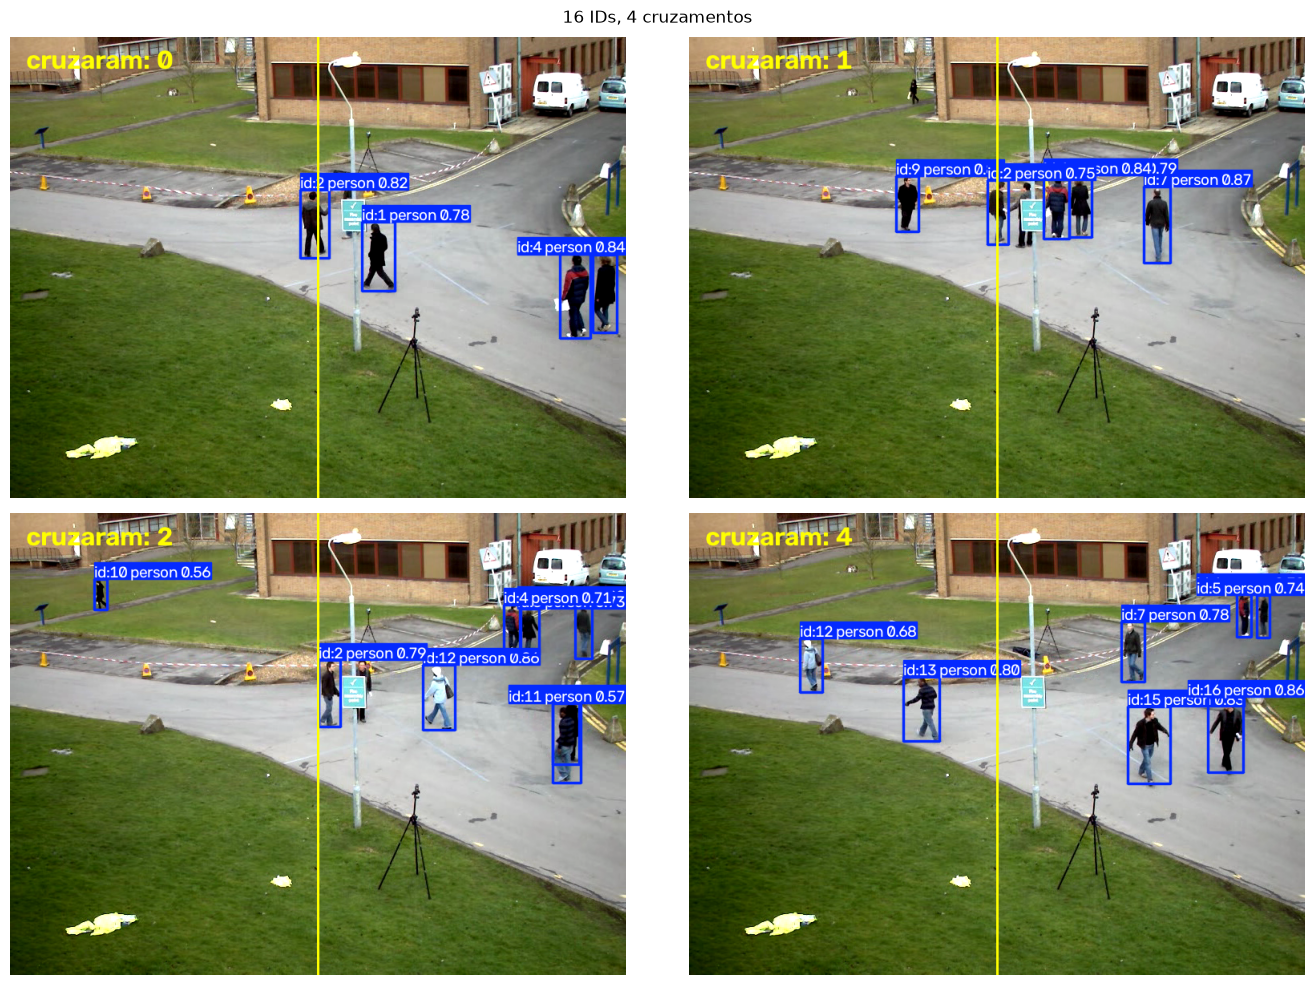

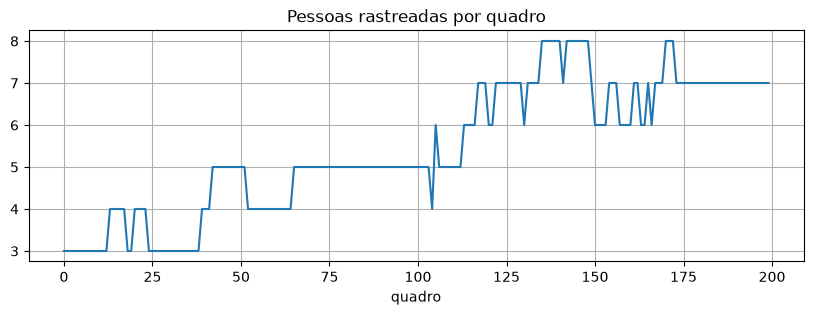

In [5]:
plt.figure(figsize=(14, 10))
for k, img in enumerate(exemplos):
    plt.subplot(2, 2, k + 1)
    plt.imshow(img)
    plt.axis("off")
plt.suptitle(f"{len(ids_vistos)} IDs, {len(cruzaram)} cruzamentos")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(por_quadro)
plt.title("Pessoas rastreadas por quadro")
plt.xlabel("quadro")
plt.grid(True)
plt.show()

## Assistir e baixar

In [6]:
web = mostrar_video("calcada_rastreada.mp4")
baixar_para_maquina(web)

Fora do Colab: o arquivo está em calcada_rastreada_web.mp4


## Exercícios

Seis exercícios para fixar a aula. Escreva a resposta na variável `resposta` e rode a célula: a função `conferir` diz na hora se está certo. Se travar, abra **Ver solução**.

Rode antes a célula de preparação abaixo. Ela só carrega as verificações.

In [7]:
# @title Preparação dos exercícios (rode, não precisa ler)
from collections import Counter
from functools import lru_cache


@lru_cache(None)
def _trilhas(n):
    m = YOLO("yolov8n.pt")
    cap = cv2.VideoCapture(video)
    pontos = []
    for _ in range(n):
        ok, frame = cap.read()
        if not ok:
            break
        r = m.track(frame, persist=True, classes=[0], verbose=False)[0]
        if r.boxes.id is not None:
            for pid, (cx, cy, _, _) in zip(r.boxes.id.int().tolist(), r.boxes.xywh.tolist()):
                pontos.append((pid, cx, cy))
    cap.release()
    return tuple(pontos)


def _cruzam_horizontal(n):
    linha, ultimo, cruzaram_h = altura // 2, {}, set()
    for pid, _, cy in _trilhas(n):
        antes = ultimo.get(pid)
        if antes is not None and (antes - linha) * (cy - linha) < 0:
            cruzaram_h.add(pid)
        ultimo[pid] = cy
    return len(cruzaram_h)


VERIFICAR = {
    1: lambda r: int(r) == max(por_quadro),
    2: lambda r: int(r) == por_quadro.index(max(por_quadro)),
    3: lambda r: abs(float(r) - sum(por_quadro) / len(por_quadro)) < 1e-3,
    4: lambda r: int(r) == len(ids_vistos - cruzaram),
    5: lambda r: int(r) == sum(n >= 50 for n in Counter(p for p, _, _ in _trilhas(100)).values()),
    6: lambda r: int(r) == _cruzam_horizontal(100),
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

### Exercício 1. Pico de movimento

Qual foi o maior número de pessoas rastreadas **ao mesmo tempo** num quadro?

<details>
<summary>Ver solução</summary>

```python
resposta = max(por_quadro)
```

</details>

In [8]:
# Dica: por_quadro guarda quantas pessoas havia em cada quadro.
resposta = None

conferir(1, resposta)

Exercício 1: ainda sem resposta.


### Exercício 2. Quando foi o pico

Em qual quadro (índice começando em 0) esse pico aconteceu pela primeira vez?

<details>
<summary>Ver solução</summary>

```python
resposta = por_quadro.index(max(por_quadro))
```

</details>

In [9]:
# Dica: Listas têm o método index().
resposta = None

conferir(2, resposta)

Exercício 2: ainda sem resposta.


### Exercício 3. Lotação média

Quantas pessoas, em média, estavam em cena por quadro?

<details>
<summary>Ver solução</summary>

```python
resposta = sum(por_quadro) / len(por_quadro)
```

</details>

In [10]:
# Dica: Soma dividida pela quantidade de quadros.
resposta = None

conferir(3, resposta)

Exercício 3: ainda sem resposta.


### Exercício 4. Quem não cruzou

Quantos IDs apareceram no vídeo mas **não** cruzaram a linha?

<details>
<summary>Ver solução</summary>

```python
resposta = len(ids_vistos - cruzaram)
```

</details>

In [11]:
# Dica: ids_vistos e cruzaram são conjuntos, e conjuntos aceitam subtração.
resposta = None

conferir(4, resposta)

Exercício 4: ainda sem resposta.


### Exercício 5. Quem ficou em cena

Rastreie de novo os primeiros 100 quadros com um modelo novo (`YOLO("yolov8n.pt")`, para os IDs começarem do zero). Quantas pessoas apareceram em **pelo menos 50** desses quadros?

<details>
<summary>Ver solução</summary>

```python
novo = YOLO("yolov8n.pt")
cap = cv2.VideoCapture(video)
aparicoes = Counter()
for _ in range(100):
    ok, frame = cap.read()
    if not ok:
        break
    r = novo.track(frame, persist=True, classes=[0], verbose=False)[0]
    if r.boxes.id is not None:
        aparicoes.update(r.boxes.id.int().tolist())
cap.release()
resposta = sum(n >= 50 for n in aparicoes.values())
```

</details>

In [12]:
# Dica: Um Counter atualizado com os IDs de cada quadro conta as aparições de cada pessoa.
novo = YOLO("yolov8n.pt")
resposta = None

conferir(5, resposta)

Exercício 5: ainda sem resposta.


### Exercício 6. Linha horizontal

Troque a linha vertical por uma **horizontal** no meio da imagem (`y = altura // 2`). Rastreando os primeiros 100 quadros com um modelo novo, quantas pessoas cruzaram essa linha?

<details>
<summary>Ver solução</summary>

```python
novo = YOLO("yolov8n.pt")
LINHA_Y = altura // 2
cap = cv2.VideoCapture(video)
ultimo_y, cruzaram_h = {}, set()
for _ in range(100):
    ok, frame = cap.read()
    if not ok:
        break
    r = novo.track(frame, persist=True, classes=[0], verbose=False)[0]
    if r.boxes.id is None:
        continue
    for pid, cy in zip(r.boxes.id.int().tolist(), r.boxes.xywh[:, 1].tolist()):
        antes = ultimo_y.get(pid)
        if antes is not None and (antes - LINHA_Y) * (cy - LINHA_Y) < 0:
            cruzaram_h.add(pid)
        ultimo_y[pid] = cy
cap.release()
resposta = len(cruzaram_h)
```

</details>

In [13]:
# Dica: É a mesma lógica da aula, trocando o centro x (coluna 0 de xywh) pelo centro y (coluna 1).
novo = YOLO("yolov8n.pt")
LINHA_Y = altura // 2
resposta = None

conferir(6, resposta)

Exercício 6: ainda sem resposta.


In [14]:
placar()

0 de 6 exercícios certos.


## O que fica

O ID é o que transforma detecção em contagem. Mas ele não é perfeito: quando uma pessoa some atrás de outra e volta, o rastreador às vezes dá um ID novo. Por isso o número de IDs costuma passar um pouco do número real de pessoas. A contagem por linha sofre menos com isso, já que só conta quem atravessa.